# Bước 1 — Feature engineering: lag + rolling (xuất khẩu tháng)

Notebook đầu pipeline: tạo feature **lag**, **MoM/YoY**, **rolling mean/std**, **rolling median/MAD** và **robust z** cho chuỗi tháng XK.

**Schema cố định:** `loai, so_luong, tri_gia, thang_nam, ten_mat_hang`  
→ đổi đường dẫn file (hoặc chạy loop) là dùng được cho mọi mặt hàng cùng cấu trúc.

**Bộ feature mặc định (chuỗi tháng):**
- Lag: `1, 2, 3, 12`
- Biến động: MoM %, YoY %, `diff(1)`
- Rolling mean/std: cửa sổ `3, 6, 12`
- Rolling robust: median + MAD + robust z cửa sổ `6, 12`

**Lưu ý**
- `sản phẩm từ sắt thép` thường thiếu `so_luong` → `don_gia` NaN; chỉ dùng `tri_gia`.
- Đây là sandbox exploratory (~66 cột). Bản compact causal (10 cột, no look-ahead) ở `4. causal_features_explore.ipynb`.
- Chạy notebook từ thư mục `scripts/` hoặc root — cell cấu hình tự resolve `ROOT`.

## 1. Cấu hình & thư viện

Chọn `DEMO_FILE`, danh sách lag / rolling / robust window. Output mặc định: `data/features/`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Chạy từ scripts/ hoặc root repo đều được
ROOT = Path("..").resolve()
if not (ROOT / "data" / "csv" / "xuat_khau").exists():
    ROOT = Path(".").resolve()

DATA_DIR = ROOT / "data" / "csv" / "xuat_khau"
FILES = [
    "gạo.csv",
    "xăng dầu các loại.csv",
    "sắt thép các loại.csv",
    "sản phẩm từ sắt thép.csv",
    "dầu thô.csv",
]

# Đổi file demo ở đây nếu muốn chạy một mặt hàng
DEMO_FILE = "gạo.csv"

VALUE_COLS = ["so_luong", "tri_gia", "don_gia"]
LAGS = [1, 2, 3, 12]
ROLL_WINDOWS = [3, 6, 12]
ROBUST_WINDOWS = [6, 12]

OUT_DIR = ROOT / "data" / "features"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"ROOT = {ROOT}")
print(f"DATA_DIR = {DATA_DIR}  exists={DATA_DIR.exists()}")
print(f"DEMO_FILE = {DEMO_FILE}")
print(f"LAGS={LAGS}, ROLL={ROLL_WINDOWS}, ROBUST={ROBUST_WINDOWS}")

ROOT = C:\Homework\Code File\ML docs\Anomaly Detection
DATA_DIR = C:\Homework\Code File\ML docs\Anomaly Detection\data\csv\xuat_khau  exists=True
DEMO_FILE = gạo.csv
LAGS=[1, 2, 3, 12], ROLL=[3, 6, 12], ROBUST=[6, 12]


## 2. Hàm tải dữ liệu & tạo feature

- `causal_baseline=False`: rolling gồm tháng hiện tại — phù hợp Isolation Forest / LOF trên feature matrix.
- `causal_baseline=True`: `shift(1)` trước rolling — baseline chỉ dùng quá khứ (no look-ahead), phù hợp control chart / so sánh `x_t` với kỳ vọng.

In [2]:
def load_series(path: Path) -> pd.DataFrame:
    """Đọc CSV tháng, index MS, thêm don_gia."""
    df = pd.read_csv(path)
    df["thang_nam"] = pd.to_datetime(df["thang_nam"])
    df = df.sort_values("thang_nam").set_index("thang_nam")
    df = df.asfreq("MS")

    qty = df["so_luong"] if "so_luong" in df.columns else pd.Series(index=df.index, dtype=float)
    val = df["tri_gia"] if "tri_gia" in df.columns else pd.Series(index=df.index, dtype=float)
    df["don_gia"] = np.where(
        qty.notna() & (qty > 0) & val.notna(),
        val / qty,
        np.nan,
    )
    return df


def add_lag_rolling(
    df: pd.DataFrame,
    value_cols=None,
    lags=None,
    roll_windows=None,
    robust_windows=None,
    causal_baseline: bool = False,
) -> pd.DataFrame:
    """Thêm lag, MoM/YoY/diff, rolling mean/std, median/MAD, robust z."""
    value_cols = value_cols or VALUE_COLS
    lags = lags or LAGS
    roll_windows = roll_windows or ROLL_WINDOWS
    robust_windows = robust_windows or ROBUST_WINDOWS

    out = df.copy()

    for col in value_cols:
        if col not in out.columns:
            continue
        s = out[col]

        for k in lags:
            out[f"{col}_lag{k}"] = s.shift(k)

        out[f"{col}_mom"] = s.pct_change(1)
        out[f"{col}_yoy"] = s.pct_change(12)
        out[f"{col}_diff1"] = s.diff(1)

        base = s.shift(1) if causal_baseline else s

        for w in roll_windows:
            min_p = max(2, w // 2)
            out[f"{col}_roll{w}_mean"] = base.rolling(w, min_periods=min_p).mean()
            out[f"{col}_roll{w}_std"] = base.rolling(w, min_periods=min_p).std()

        for w in robust_windows:
            min_p = max(3, w // 2)
            med = base.rolling(w, min_periods=min_p).median()
            mad = (base - med).abs().rolling(w, min_periods=min_p).median()
            out[f"{col}_roll{w}_median"] = med
            out[f"{col}_roll{w}_mad"] = mad
            scale = 1.4826 * mad.replace(0, np.nan)
            out[f"{col}_robust_z{w}"] = (s - med) / scale

        if f"{col}_roll12_mean" in out.columns:
            out[f"{col}_dev_roll12"] = s - out[f"{col}_roll12_mean"]

    return out

def build_features(path: Path, causal_baseline: bool = False) -> pd.DataFrame:
    raw = load_series(path)
    feat = add_lag_rolling(raw, causal_baseline=causal_baseline)
    feat["source_file"] = path.name
    if "ten_mat_hang" in raw.columns and raw["ten_mat_hang"].notna().any():
        feat["ten_mat_hang"] = raw["ten_mat_hang"].dropna().iloc[0]
    else:
        feat["ten_mat_hang"] = path.stem
    return feat


def feature_columns(df: pd.DataFrame) -> list[str]:
    prefixes = ("so_luong", "tri_gia", "don_gia")
    return [c for c in df.columns if c.startswith(prefixes)]


print("Functions ready: load_series, add_lag_rolling, build_features")

Functions ready: load_series, add_lag_rolling, build_features


## 3. Demo một file

Đổi `DEMO_FILE` ở cell cấu hình rồi chạy lại từ đầu nếu muốn mặt hàng khác.
In shape, vài cột feature, và tỷ lệ missing.


In [3]:
demo_path = DATA_DIR / DEMO_FILE
assert demo_path.exists(), f"Không thấy file: {demo_path.resolve()}"

raw = load_series(demo_path)
feat = build_features(demo_path, causal_baseline=False)

print(f"File: {demo_path.name}")
print(f"Kỳ: {feat.index.min().date()} → {feat.index.max().date()} ({len(feat)} tháng)")
print(f"so_luong hợp lệ: {feat['so_luong'].notna().sum()} / {len(feat)}")
print(f"tri_gia hợp lệ:  {feat['tri_gia'].notna().sum()} / {len(feat)}")
print(f"Số cột feature: {len(feature_columns(feat))}")
print("\nCột feature:")
print(feature_columns(feat))

feat[feature_columns(feat)].head(15)

File: gạo.csv
Kỳ: 2009-01-01 → 2026-08-01 (212 tháng)
so_luong hợp lệ: 212 / 212
tri_gia hợp lệ:  212 / 212
Số cột feature: 63

Cột feature:
['so_luong', 'tri_gia', 'don_gia', 'so_luong_lag1', 'so_luong_lag2', 'so_luong_lag3', 'so_luong_lag12', 'so_luong_mom', 'so_luong_yoy', 'so_luong_diff1', 'so_luong_roll3_mean', 'so_luong_roll3_std', 'so_luong_roll6_mean', 'so_luong_roll6_std', 'so_luong_roll12_mean', 'so_luong_roll12_std', 'so_luong_roll6_median', 'so_luong_roll6_mad', 'so_luong_robust_z6', 'so_luong_roll12_median', 'so_luong_roll12_mad', 'so_luong_robust_z12', 'so_luong_dev_roll12', 'tri_gia_lag1', 'tri_gia_lag2', 'tri_gia_lag3', 'tri_gia_lag12', 'tri_gia_mom', 'tri_gia_yoy', 'tri_gia_diff1', 'tri_gia_roll3_mean', 'tri_gia_roll3_std', 'tri_gia_roll6_mean', 'tri_gia_roll6_std', 'tri_gia_roll12_mean', 'tri_gia_roll12_std', 'tri_gia_roll6_median', 'tri_gia_roll6_mad', 'tri_gia_robust_z6', 'tri_gia_roll12_median', 'tri_gia_roll12_mad', 'tri_gia_robust_z12', 'tri_gia_dev_roll12', 'don

,so_luong,tri_gia,don_gia,so_luong_lag1,so_luong_lag2,so_luong_lag3,so_luong_lag12,so_luong_mom,so_luong_yoy,so_luong_diff1,...,don_gia_roll6_std,don_gia_roll12_mean,don_gia_roll12_std,don_gia_roll6_median,don_gia_roll6_mad,don_gia_robust_z6,don_gia_roll12_median,don_gia_roll12_mad,don_gia_robust_z12,don_gia_dev_roll12
thang_nam,,,,,,,,,,,,,,,,,,,,,
2009-01-01,302318.0,127975151.0,423.313038,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-02-01,737762.0,340794058.0,461.929536,302318.0,NaN,NaN,NaN,1.440351,NaN,435444.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2009-03-01,740371.0,344198004.0,464.899360,737762.0,302318.0,NaN,NaN,0.003536,NaN,2609.0,...,23.200129,NaN,NaN,461.929536,NaN,NaN,NaN,NaN,NaN,NaN
2009-04-01,705377.0,345310324.0,489.540096,740371.0,737762.0,302318.0,NaN,-0.047265,NaN,-34994.0,...,27.363309,NaN,NaN,463.414448,NaN,NaN,NaN,NaN,NaN,NaN
2009-05-01,664282.0,332889328.0,501.126522,705377.0,740371.0,737762.0,NaN,-0.058260,NaN,-41095.0,...,30.019163,NaN,NaN,464.899360,26.125648,0.935283,NaN,NaN,NaN,NaN
2009-06-01,574686.0,256449236.0,446.242358,664282.0,705377.0,740371.0,NaN,-0.134876,NaN,-89596.0,...,28.301880,464.508485,28.301880,463.414448,21.648869,-0.535013,463.414448,NaN,NaN,-18.266126
2009-07-01,486544.0,199338050.0,409.702000,574686.0,664282.0,705377.0,NaN,-0.153374,NaN,-88142.0,...,32.498589,456.678987,33.115016,463.414448,26.125648,-1.386704,461.929536,NaN,NaN,-46.976987
2009-08-01,423307.0,169078443.0,399.422743,486544.0,574686.0,664282.0,NaN,-0.129972,NaN,-63237.0,...,41.413807,449.521957,36.738688,455.570859,31.176405,-1.214745,454.085947,NaN,NaN,-50.099214
2009-09-01,350720.0,130120701.0,371.010210,423307.0,486544.0,574686.0,NaN,-0.171476,NaN,-72587.0,...,51.895825,440.798429,43.196229,427.972179,44.969805,-0.854358,446.242358,NaN,NaN,-69.788219


## 4. Chạy tất cả file cùng schema

Lặp toàn bộ `FILES`, bỏ qua file lỗi, lưu dict `all_feats[stem]`.


In [4]:
all_feats: dict[str, pd.DataFrame] = {}
summary_rows = []

for name in FILES:
    path = DATA_DIR / name
    if not path.exists():
        print(f"MISSING: {path}")
        continue

    f = build_features(path, causal_baseline=False)
    all_feats[name] = f

    summary_rows.append({
        "file": name,
        "ten_mat_hang": f["ten_mat_hang"].iloc[0],
        "n_months": len(f),
        "so_luong_valid": int(f["so_luong"].notna().sum()),
        "tri_gia_valid": int(f["tri_gia"].notna().sum()),
        "don_gia_valid": int(f["don_gia"].notna().sum()),
        "n_feature_cols": len(feature_columns(f)),
        "start": f.index.min().date(),
        "end": f.index.max().date(),
    })

summary = pd.DataFrame(summary_rows)
summary

C:\Users\minht\AppData\Local\Temp\ipykernel_4756\1177062984.py:42: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  out[f"{col}_mom"] = s.pct_change(1)
C:\Users\minht\AppData\Local\Temp\ipykernel_4756\1177062984.py:43: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  out[f"{col}_yoy"] = s.pct_change(12)
C:\Users\minht\AppData\Local\Temp\ipykernel_4756\1177062984.py:42: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA v

,file,ten_mat_hang,n_months,so_luong_valid,tri_gia_valid,don_gia_valid,n_feature_cols,start,end
0,gạo.csv,gạo,212,212,212,212,63,2009-01-01,2026-08-01
1,xăng dầu các loại.csv,xăng dầu các loại,212,212,212,212,63,2009-01-01,2026-08-01
2,sắt thép các loại.csv,sắt thép các loại,212,212,212,212,63,2009-01-01,2026-08-01
3,sản phẩm từ sắt thép.csv,sản phẩm từ sắt thép,212,0,212,0,63,2009-01-01,2026-08-01
4,dầu thô.csv,dầu thô,212,212,212,212,63,2009-01-01,2026-08-01


## 5. Feature matrix sẵn sàng cho model

`make_model_matrix` chọn cột số (loại id) để đưa vào Isolation Forest / LOF sau này.
Bản compact causal (10 cột, no look-ahead) nằm ở `4. causal_features_explore.ipynb`.


In [5]:
def make_model_matrix(feat: pd.DataFrame) -> pd.DataFrame:
    cols = feature_columns(feat)
    # bỏ cột toàn NaN (vd. so_luong_* khi thiếu lượng)
    usable = [c for c in cols if feat[c].notna().any()]
    return feat[usable].dropna()


X_demo = make_model_matrix(feat)
print(f"{DEMO_FILE}: X shape = {X_demo.shape}")
print(f"Kỳ còn lại: {X_demo.index.min().date()} → {X_demo.index.max().date()}")
X_demo.tail()

gạo.csv: X shape = (200, 63)
Kỳ còn lại: 2010-01-01 → 2026-08-01


,so_luong,tri_gia,don_gia,so_luong_lag1,so_luong_lag2,so_luong_lag3,so_luong_lag12,so_luong_mom,so_luong_yoy,so_luong_diff1,...,don_gia_roll6_std,don_gia_roll12_mean,don_gia_roll12_std,don_gia_roll6_median,don_gia_roll6_mad,don_gia_robust_z6,don_gia_roll12_median,don_gia_roll12_mad,don_gia_robust_z12,don_gia_dev_roll12
thang_nam,,,,,,,,,,,,,,,,,,,,,
2026-04-01,1107362.0,513943569.0,464.115230,1008944.0,621837.0,651430.0,1113043.0,0.097546,-0.005104,98418.0,...,17.534564,493.012912,24.519134,475.247594,17.483968,-0.429461,489.871945,26.031479,-0.667371,-28.897682
2026-05-01,902228.0,430234520.0,476.857867,1107362.0,1008944.0,621837.0,775490.0,-0.185246,0.163430,-205134.0,...,8.067884,488.932242,22.558083,475.247594,17.483968,0.062121,479.968122,24.816063,-0.084535,-12.074375
2026-06-01,755975.0,375840457.0,497.159902,902228.0,1107362.0,1008944.0,519779.0,-0.162102,0.454416,-146253.0,...,13.526672,486.469925,19.459726,475.247594,16.522336,0.894525,479.968122,23.606023,0.491218,10.689977
2026-07-01,471814.0,241109140.0,511.025828,755975.0,902228.0,1107362.0,786007.0,-0.375887,-0.399733,-284161.0,...,20.244120,488.798879,20.652739,475.818338,16.522336,1.437274,486.761691,23.606023,0.693295,22.226949
2026-08-01,538856.0,279632687.0,518.937688,471814.0,755975.0,902228.0,851158.0,0.142094,-0.366914,67042.0,...,21.926163,490.093493,22.088390,487.008885,16.522336,1.303428,486.761691,24.069773,0.901646,28.844195


In [6]:
# Ma trận theo từng file
matrices = {}
for name, f in all_feats.items():
    X = make_model_matrix(f)
    matrices[name] = X
    print(f"{name:30s}  X={X.shape[0]:3d} x {X.shape[1]:3d}  "
          f"({X.index.min().date()} → {X.index.max().date()})")

gạo.csv                         X=200 x  63  (2010-01-01 → 2026-08-01)
xăng dầu các loại.csv           X=200 x  63  (2010-01-01 → 2026-08-01)
sắt thép các loại.csv           X=200 x  63  (2010-01-01 → 2026-08-01)
sản phẩm từ sắt thép.csv        X=200 x  21  (2010-01-01 → 2026-08-01)
dầu thô.csv                     X=200 x  63  (2010-01-01 → 2026-08-01)


## 6. Kiểm tra nhanh vài feature (demo file)

Vẽ mức gốc cùng robust z / MoM để kiểm tra sanity (spike, mùa vụ, NaN đầu chuỗi).


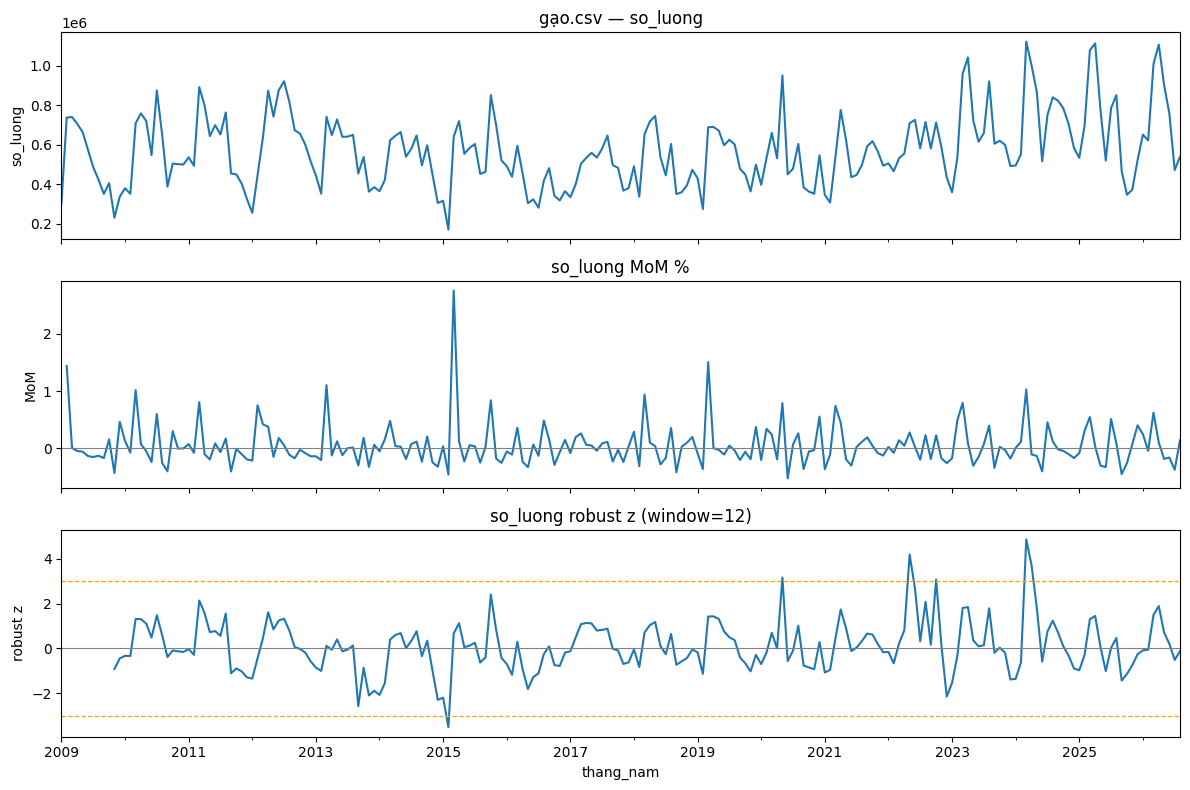

In [7]:
plot_col = "so_luong" if feat["so_luong"].notna().sum() > 12 else "tri_gia"

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

feat[plot_col].plot(ax=axes[0], title=f"{DEMO_FILE} — {plot_col}")
axes[0].set_ylabel(plot_col)

if f"{plot_col}_mom" in feat.columns:
    feat[f"{plot_col}_mom"].plot(ax=axes[1], title=f"{plot_col} MoM %")
    axes[1].axhline(0, color="gray", lw=0.8)
    axes[1].set_ylabel("MoM")

zcol = f"{plot_col}_robust_z12"
if zcol in feat.columns:
    feat[zcol].plot(ax=axes[2], title=f"{plot_col} robust z (window=12)")
    axes[2].axhline(3, color="orange", ls="--", lw=0.9)
    axes[2].axhline(-3, color="orange", ls="--", lw=0.9)
    axes[2].axhline(0, color="gray", lw=0.8)
    axes[2].set_ylabel("robust z")

plt.tight_layout()
plt.show()

## 7. Lưu feature ra CSV (tùy chọn)

Ghi `data/features/{stem}_lag_rolling.csv` cho từng file đã build thành công.


In [8]:
saved = []
for name, f in all_feats.items():
    out_name = Path(name).stem + "_features.csv"
    out_path = OUT_DIR / out_name
    f.to_csv(out_path, index=True)
    saved.append(str(out_path))
    print(f"Saved: {out_path}  ({f.shape[0]} rows, {f.shape[1]} cols)")

print(f"\nĐã lưu {len(saved)} file vào {OUT_DIR.resolve()}")

Saved: C:\Homework\Code File\ML docs\Anomaly Detection\data\features\gạo_features.csv  (212 rows, 66 cols)
Saved: C:\Homework\Code File\ML docs\Anomaly Detection\data\features\xăng dầu các loại_features.csv  (212 rows, 66 cols)
Saved: C:\Homework\Code File\ML docs\Anomaly Detection\data\features\sắt thép các loại_features.csv  (212 rows, 66 cols)
Saved: C:\Homework\Code File\ML docs\Anomaly Detection\data\features\sản phẩm từ sắt thép_features.csv  (212 rows, 66 cols)
Saved: C:\Homework\Code File\ML docs\Anomaly Detection\data\features\dầu thô_features.csv  (212 rows, 66 cols)

Đã lưu 5 file vào C:\Homework\Code File\ML docs\Anomaly Detection\data\features


## 8. Gợi ý dùng tiếp

| Mục tiêu | File / cách dùng |
|---|---|
| Isolation Forest / LOF (exploratory) | `make_model_matrix(feat)` rồi fit từng mặt hàng |
| Control chart / alert | `build_features(..., causal_baseline=True)` → `*_robust_z12` |
| Baseline ETS | `rice_alert_prototype.ipynb` rồi `2. ets_tier1_explore.ipynb` |
| Feature causal 10 cột (IF benchmark) | `4. causal_features_explore.ipynb` |

Đổi `DEMO_FILE` hoặc thêm tên vào `FILES` nếu có mặt hàng mới cùng schema.